# 01 · Data

Every Binance USDT perp that ever traded, **delisted included**, from the data.binance.vision
archive: monthly daily klines + funding → `data/binance_archive/`. No survivorship bias. ~15 min
the first time; reruns only fetch what is missing. Settings in `config/fetch_config.yaml`.

In [1]:
# run from the project root (works from research/ or any subfolder); the strategy package is
# in src/, the data download and plot style in research/lib
import os, sys
while not os.path.isdir("config") and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir("..")
sys.path[:0] = [os.path.abspath("src"), os.path.abspath("research/lib")]

In [2]:
import logging, yaml
import pandas as pd, matplotlib.pyplot as plt
from feeds import fetch_archive, list_archive_symbols, non_crypto_symbols
from betafunding.data import load_panel
from plotstyle import *
apply()
logging.basicConfig(level=logging.WARNING, format="%(asctime)s %(levelname)s %(message)s", force=True)
a = yaml.safe_load(open("config/fetch_config.yaml"))["archive"]

## 1. Universe

In [3]:
allsym = [s for s in list_archive_symbols() if s.endswith("USDT")]
SYMS = [s for s in allsym if s not in non_crypto_symbols() and s not in set(a["exclude"])]
print(f"{len(allsym)} USDT symbols in the archive -> {len(SYMS)} crypto perps")

900 USDT symbols in the archive -> 679 crypto perps


## 2. Fetch

In [4]:
res = fetch_archive(SYMS, a["start"], a["end"], a["timeframe"], a["data_root"])
print(f"{(res.bars != 0).sum()} symbols with data in {a['start']} .. {a['end']}")

667 symbols with data in 2024-01 .. 2026-09


## 3. What landed on disk

In [5]:
panel = load_panel(a["data_root"], a["timeframe"])
trading = panel.dollar_volume.fillna(0) > 0
first = trading.idxmax().where(trading.any())
last = trading[::-1].idxmax().where(trading.any())
end = trading.index.max()
gone = last[last < end - pd.Timedelta(days=7)]
print(f"{trading.shape[1]} contracts; {len(gone)} stopped trading inside the window")
pd.DataFrame({"listed": first.dt.date, "last traded": last.dt.date}).loc[gone.sort_values().index].tail(10)

667 contracts; 135 stopped trading inside the window


,listed,last traded
IP,2025-02-13,2026-06-28
AERGO,2024-09-10,2026-06-30
NFP,2024-01-01,2026-07-02
ACX,2024-12-06,2026-08-07
VANRY,2024-03-13,2026-08-07
HFT,2024-01-01,2026-08-07
VIC,2025-03-12,2026-08-07
ICX,2024-01-01,2026-08-26
SCRT,2024-11-21,2026-08-26
STORJ,2024-01-01,2026-08-26


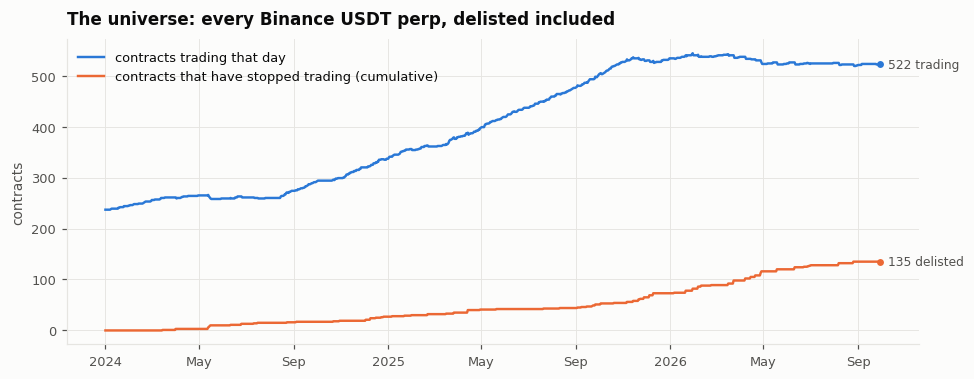

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.6))
live = trading.sum(axis=1)
dead = gone.value_counts().sort_index().cumsum().reindex(trading.index).ffill().fillna(0)
ax.plot(live.index, live, color=SERIES[0], label="contracts trading that day")
ax.plot(dead.index, dead, color=SERIES[1], label="contracts that have stopped trading (cumulative)")
end_label(ax, live, f"{int(live.iloc[-1])} trading", SERIES[0])
end_label(ax, dead, f"{int(dead.iloc[-1])} delisted", SERIES[1])
ax.set_title("The universe: every Binance USDT perp, delisted included"); ax.set_ylabel("contracts")
ax.legend(loc="upper left"); save(fig, "universe"); plt.show()